# LINET strokes / flashes vs MTG-LI — September 2024

Three sources compared:
- LINET strokes — individual return strokes
- LINET flashes — flash-level aggregation (provided by Stefano)
- LI uncorrected — MTG Lightning Imager groups, before parallax correction

Uses `data_io.py` and `plot_histograms.py` from the same folder.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from data_io import read_strokes, read_strokes_dir, summary, DOMAIN
import plot_histograms as ph

plt.rcParams["figure.dpi"] = 110

## 2. Parameters

In [11]:
LINET_DIR = Path("../linet_data")
LI_DIR    = Path("../LI_september/daily")


PATTERN_STROKES  = "LinetStrokesData*.txt"
PATTERN_FLASHES  = "LinetFlashesData*.txt"
PATTERN_LI       = "*_uncorrected*.txt"

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

print("Domain:", DOMAIN)

Domain: {'lon_min': 6.0, 'lon_max': 18.0, 'lat_min': 37.0, 'lat_max': 47.0}


## 3. Load all sources into one dict

Dict key = label that appears on plots. Order matters for color assignment
(see `DEFAULT_COLORS` in `plot_histograms.py`).

In [12]:
print("=== LINET strokes ===")
linet_strokes = read_strokes_dir(LINET_DIR, pattern=PATTERN_STROKES, domain=DOMAIN)
summary(linet_strokes, "LINET strokes")

=== LINET strokes ===
  LinetStrokesData20240901.txt:   27119 strokes (in domain)
  LinetStrokesData20240902.txt:  155127 strokes (in domain)
  LinetStrokesData20240903.txt:  188623 strokes (in domain)
  LinetStrokesData20240904.txt:  430929 strokes (in domain)
  LinetStrokesData20240905.txt:  634774 strokes (in domain)
  LinetStrokesData20240906.txt:   29222 strokes (in domain)
  LinetStrokesData20240907.txt:   16472 strokes (in domain)
  LinetStrokesData20240908.txt:  184255 strokes (in domain)
  LinetStrokesData20240909.txt:   98254 strokes (in domain)
  LinetStrokesData20240910.txt:   33614 strokes (in domain)
  LinetStrokesData20240911.txt:   21971 strokes (in domain)
  LinetStrokesData20240912.txt:  150850 strokes (in domain)
  LinetStrokesData20240913.txt:   21914 strokes (in domain)
  LinetStrokesData20240914.txt:    5126 strokes (in domain)
  LinetStrokesData20240915.txt:       9 strokes (in domain)
  LinetStrokesData20240916.txt:   10211 strokes (in domain)
  LinetStrokesData

In [13]:
print("=== LINET flashes ===")
linet_flashes = read_strokes_dir(LINET_DIR, pattern=PATTERN_FLASHES, domain=DOMAIN)
summary(linet_flashes, "LINET flashes")

=== LINET flashes ===
  LinetFlashesData20240901.txt:   12565 strokes (in domain)
  LinetFlashesData20240902.txt:   50097 strokes (in domain)
  LinetFlashesData20240903.txt:   74725 strokes (in domain)
  LinetFlashesData20240904.txt:  167515 strokes (in domain)
  LinetFlashesData20240905.txt:  216238 strokes (in domain)
  LinetFlashesData20240906.txt:   13055 strokes (in domain)
  LinetFlashesData20240907.txt:    9909 strokes (in domain)
  LinetFlashesData20240908.txt:   89553 strokes (in domain)
  LinetFlashesData20240909.txt:   35468 strokes (in domain)
  LinetFlashesData20240910.txt:   12204 strokes (in domain)
  LinetFlashesData20240911.txt:    8638 strokes (in domain)
  LinetFlashesData20240912.txt:   43573 strokes (in domain)
  LinetFlashesData20240913.txt:    8109 strokes (in domain)
  LinetFlashesData20240914.txt:    1996 strokes (in domain)
  LinetFlashesData20240915.txt:       6 strokes (in domain)
  LinetFlashesData20240916.txt:    3645 strokes (in domain)
  LinetFlashesData

In [14]:
print("=== LI uncorrected ===")
li = read_strokes_dir(LI_DIR, pattern=PATTERN_LI, domain=DOMAIN)
summary(li, "LI uncorrected")

=== LI uncorrected ===
  LI_uncorrected_20240901.txt:   18583 strokes (in domain)
  LI_uncorrected_20240902.txt:   54679 strokes (in domain)
  LI_uncorrected_20240903.txt:   98267 strokes (in domain)
  LI_uncorrected_20240904.txt:  260836 strokes (in domain)
  LI_uncorrected_20240905.txt:  249974 strokes (in domain)
  LI_uncorrected_20240906.txt:    7419 strokes (in domain)
  LI_uncorrected_20240907.txt:   23118 strokes (in domain)
  LI_uncorrected_20240908.txt:  143813 strokes (in domain)
  LI_uncorrected_20240909.txt:   59059 strokes (in domain)
  LI_uncorrected_20240910.txt:   19453 strokes (in domain)
  LI_uncorrected_20240911.txt:   17409 strokes (in domain)
  LI_uncorrected_20240912.txt:   47993 strokes (in domain)
  LI_uncorrected_20240913.txt:    9578 strokes (in domain)
  LI_uncorrected_20240914.txt:    2354 strokes (in domain)
  LI_uncorrected_20240915.txt:       8 strokes (in domain)
  LI_uncorrected_20240916.txt:    4284 strokes (in domain)
  LI_uncorrected_20240917.txt:   

In [15]:
# Bundle everything into a single dict — this is what all plotting functions take.
# Adding a 4th source later is trivial: just add a new key/value.
sources = {
    "LINET strokes":  linet_strokes,
    "LINET flashes":  linet_flashes,
    "LI uncorrected": li,
}

ph.print_summary_table(sources)


--- summary ---
  LINET strokes       :    2808847
  LINET flashes       :     998706
  LI uncorrected      :    1342334

  ratios (rows / cols):
                           LINET strokes   LINET flashes  LI uncorrected
  LINET strokes                    1.00×           2.81×           2.09×
  LINET flashes                    0.36×           1.00×           0.74×
  LI uncorrected                   0.48×           1.34×           1.00×


## 4. Diurnal cycle — sanity check

Main check for timezone / data consistency. All three curves should peak at the same hour UTC.

  saved plots/diurnal_normalized.png


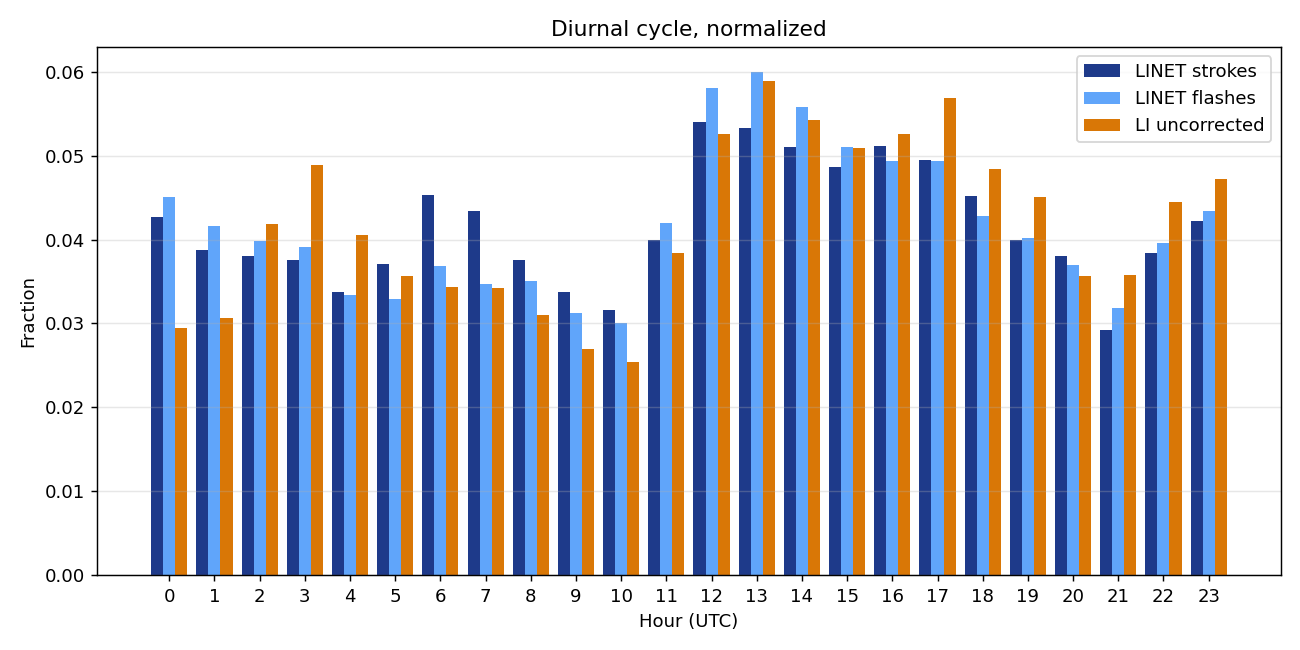

In [16]:
ph.plot_diurnal(sources, PLOTS_DIR / "diurnal_normalized.png", normalize=True)

from IPython.display import Image
Image(str(PLOTS_DIR / "diurnal_normalized.png"))

  saved plots/diurnal_raw.png


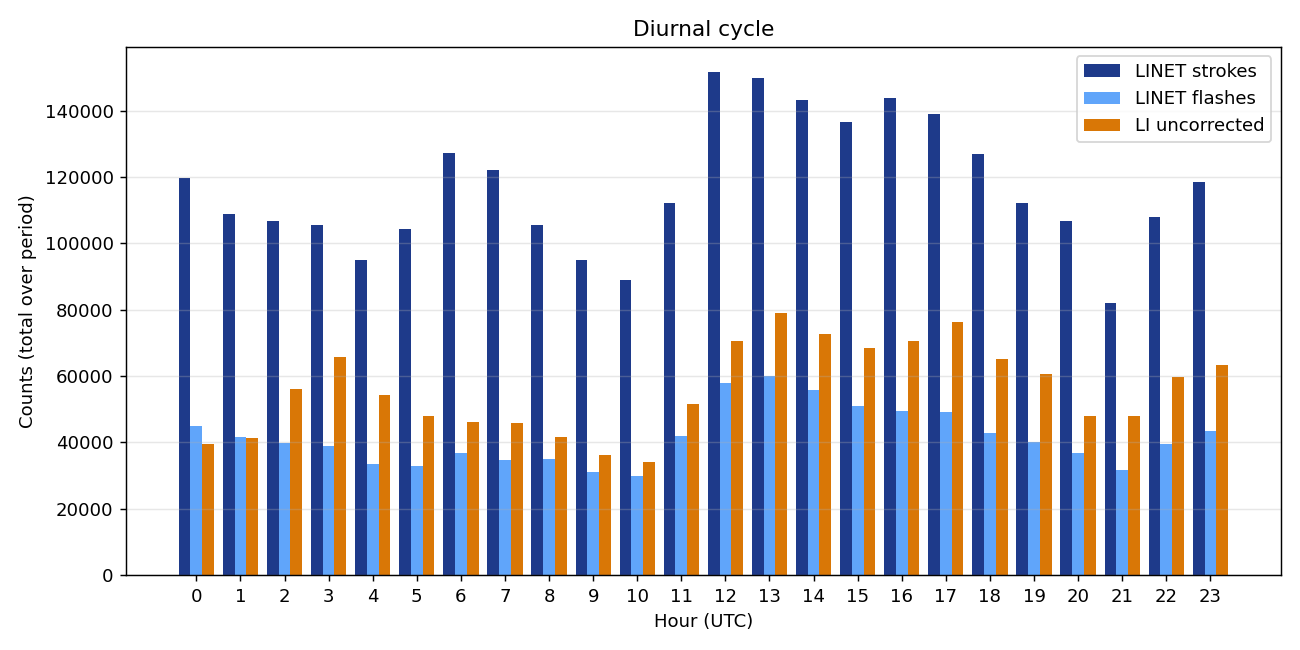

In [17]:
ph.plot_diurnal(sources, PLOTS_DIR / "diurnal_raw.png", normalize=False)
Image(str(PLOTS_DIR / "diurnal_raw.png"))

## 5. Daily counts over the month

  saved plots/daily.png


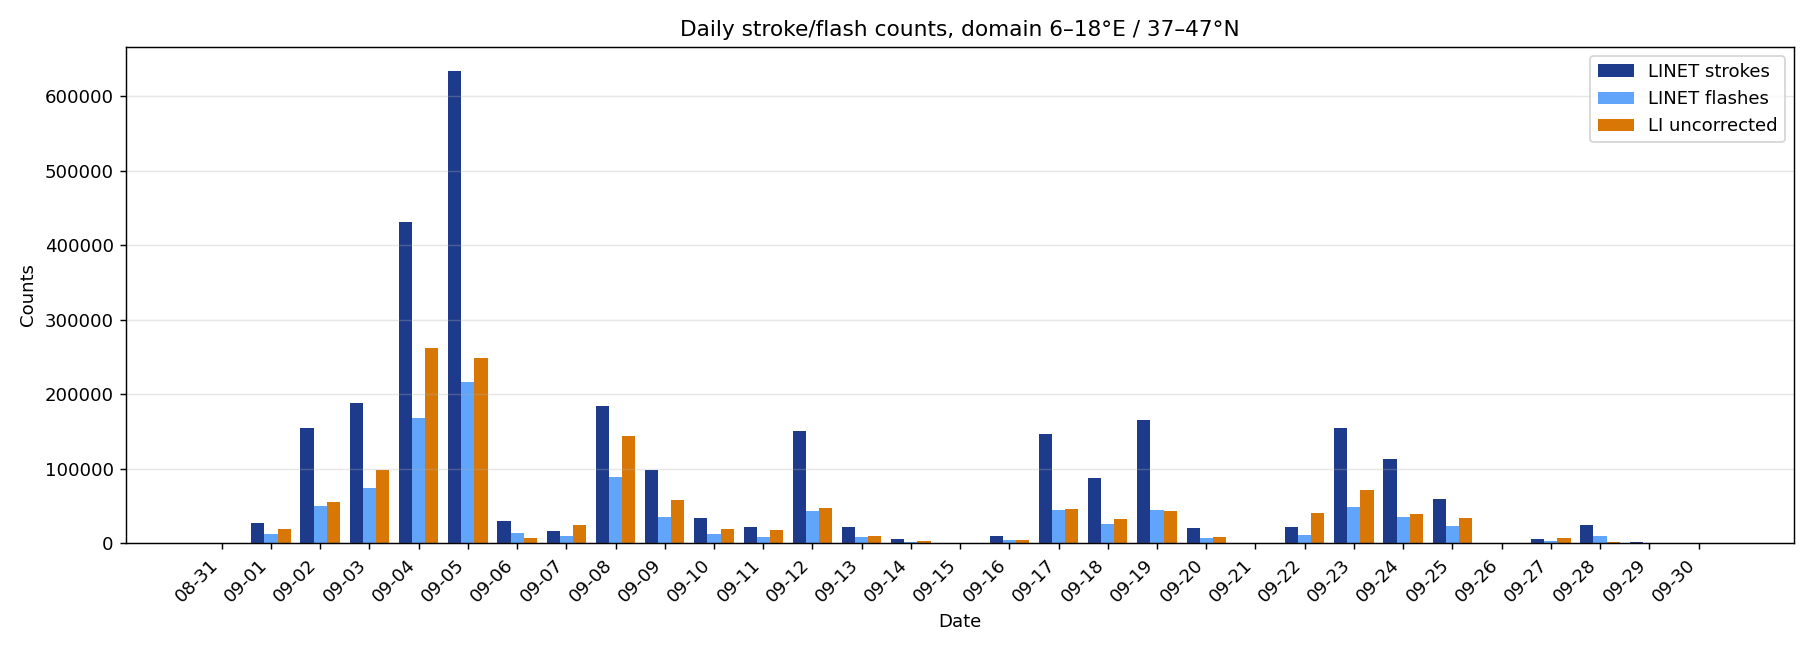

In [18]:
ph.plot_daily(sources, PLOTS_DIR / "daily.png", log=False)
Image(str(PLOTS_DIR / "daily.png"))

  saved plots/daily_log.png


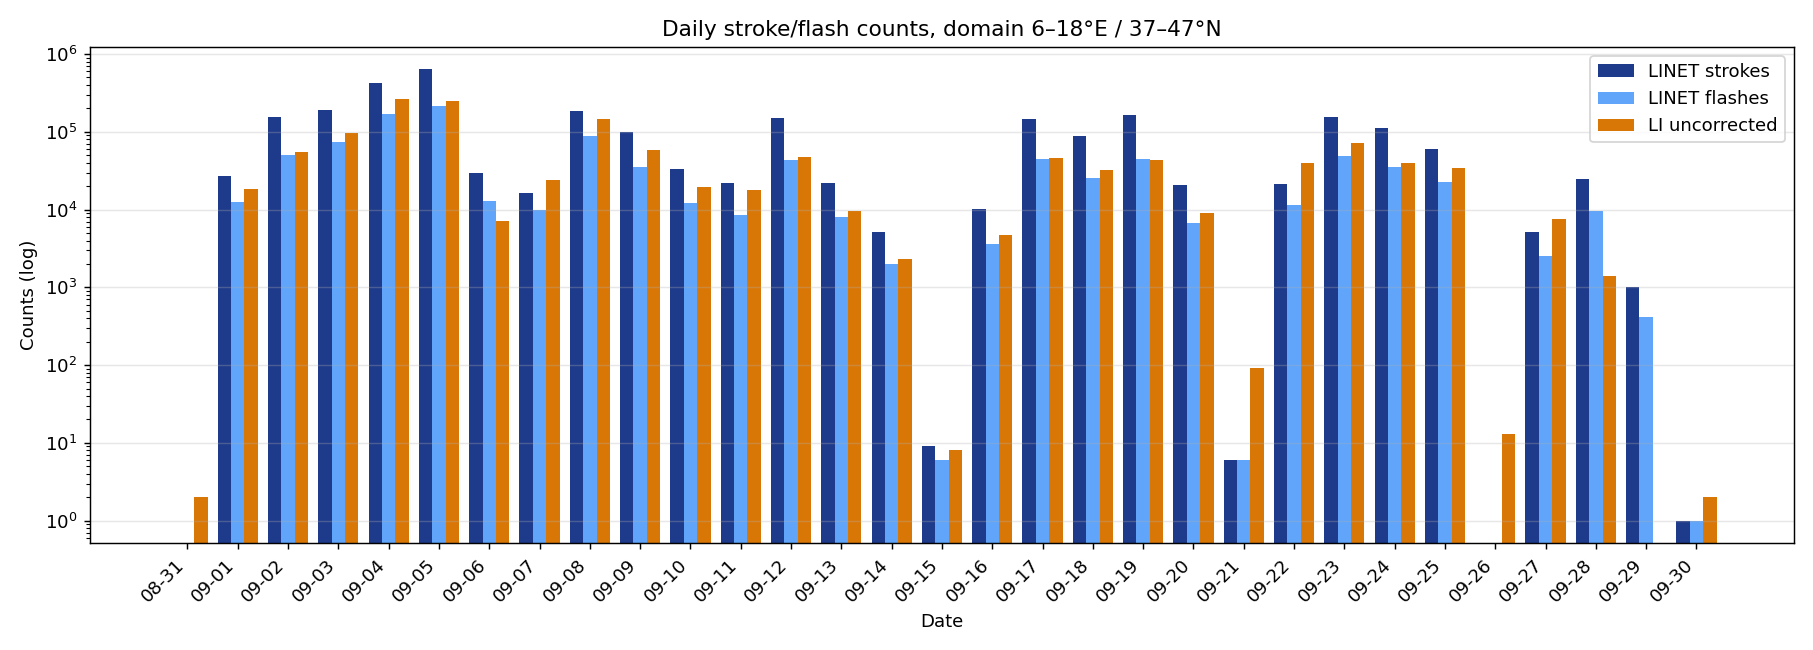

In [19]:
ph.plot_daily(sources, PLOTS_DIR / "daily_log.png", log=True)
Image(str(PLOTS_DIR / "daily_log.png"))

## 6. Hourly per day grid

  saved plots/hourly_per_day.png


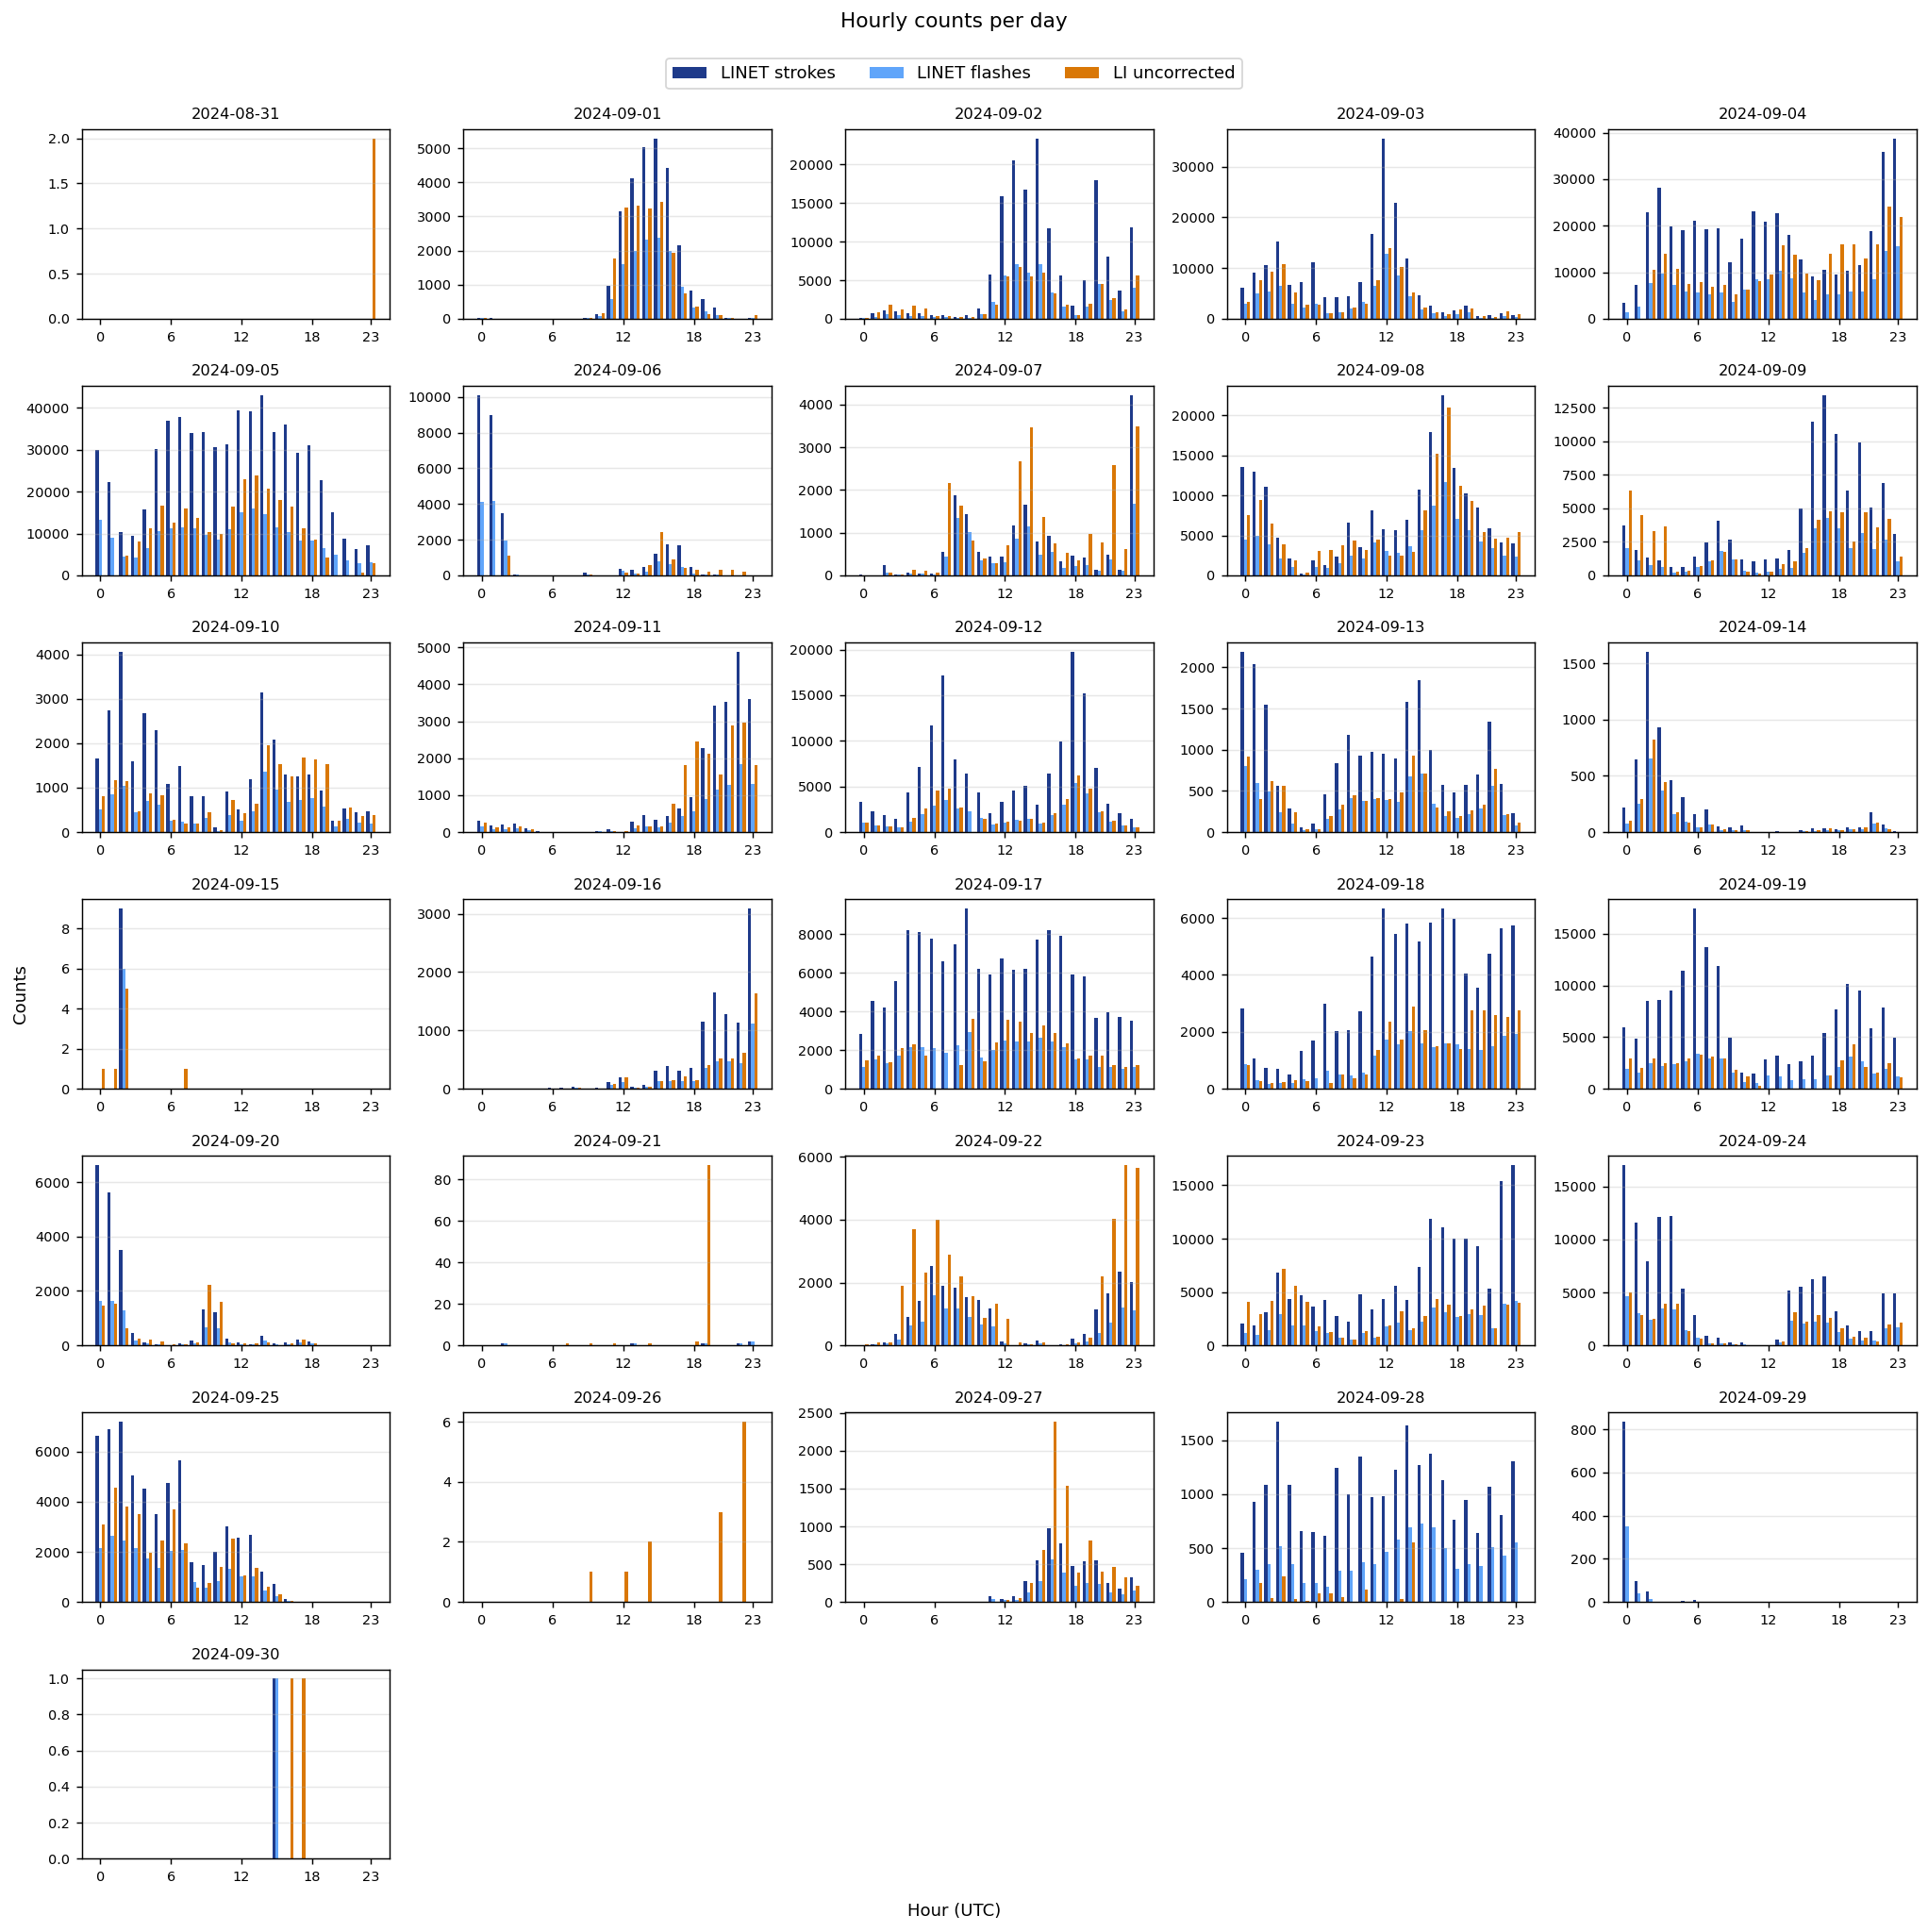

In [20]:
ph.plot_hourly_per_day(sources, PLOTS_DIR / "hourly_per_day.png", ncols=5)
Image(str(PLOTS_DIR / "hourly_per_day.png"))

## 7. Zoom into one day

Change `DAY` to inspect a single day in detail — hourly histogram + scatter on the map.

In [21]:
DAY = pd.Timestamp("2024-09-05").date()

# Filter every source to that day
day_sources = {name: df[df["datetime"].dt.date == DAY]
               for name, df in sources.items()}

for name, df in day_sources.items():
    print(f"  {name}: {len(df)}")

  LINET strokes: 634774
  LINET flashes: 216238
  LI uncorrected: 248752


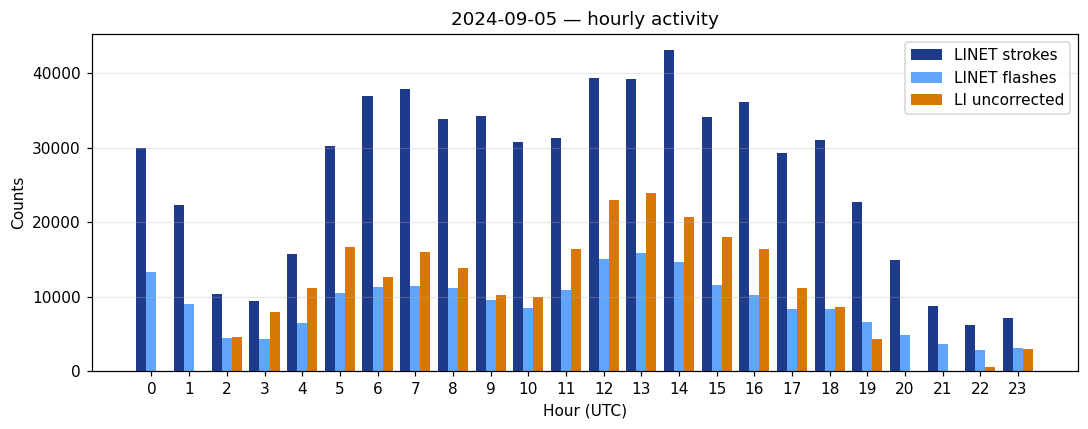

In [22]:
# Hourly counts on that day, side-by-side
x = np.arange(24)
n = len(day_sources)
offsets, w = ph._bar_offsets(n)
cols = ph._colors_for(day_sources)

fig, ax = plt.subplots(figsize=(10, 4))
for (name, df), off, c in zip(day_sources.items(), offsets, cols):
    h = df.groupby(df["datetime"].dt.hour).size().reindex(range(24), fill_value=0)
    ax.bar(x + off, h.values, w, label=name, color=c)
ax.set_xticks(x)
ax.set_xlabel("Hour (UTC)")
ax.set_ylabel("Counts")
ax.set_title(f"{DAY} — hourly activity")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

/var/folders/jd/kcv7p1l15652b06l613vq_980000gn/T/ipykernel_74856/2563723792.py:14: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/Users/macboook/anaconda3/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


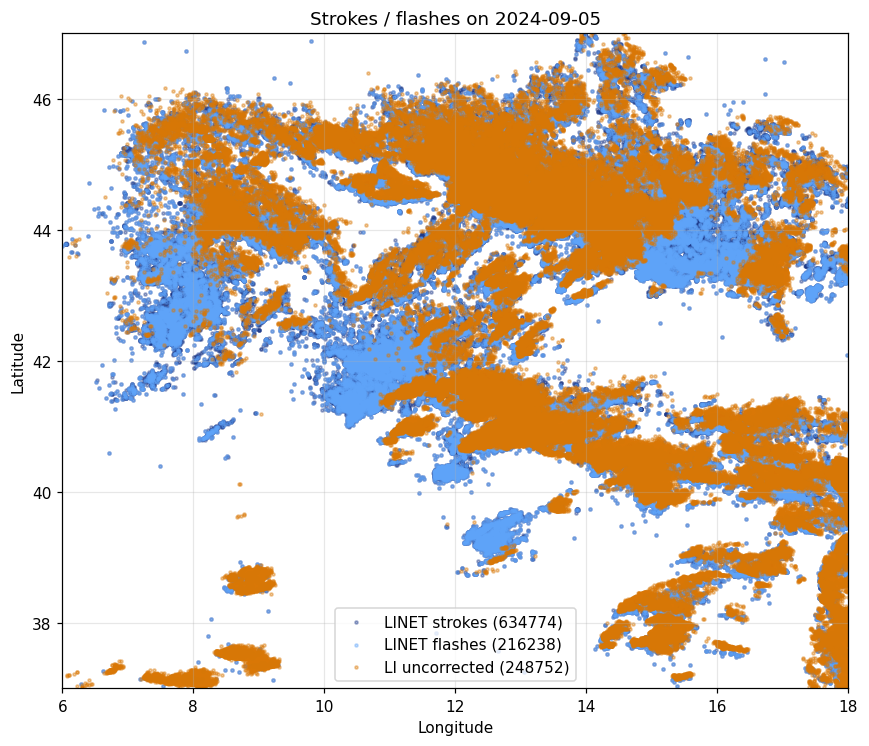

In [23]:
# Scatter on the map — visualise spatial agreement / parallax shift
fig, ax = plt.subplots(figsize=(8, 7))
for (name, df), c in zip(day_sources.items(), ph._colors_for(day_sources)):
    ax.scatter(df["lon"], df["lat"], s=4, alpha=0.4, color=c,
               label=f"{name} ({len(df)})")
ax.set_xlim(DOMAIN["lon_min"], DOMAIN["lon_max"])
ax.set_ylim(DOMAIN["lat_min"], DOMAIN["lat_max"])
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_aspect("equal")
ax.set_title(f"Strokes / flashes on {DAY}")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Save the full set of plots

In [24]:
ph.plot_all(sources, outdir=PLOTS_DIR)

Saving plots to plots/
  saved plots/daily_counts.png
  saved plots/daily_counts_log.png
  saved plots/hourly_per_day.png
  saved plots/diurnal_raw.png
  saved plots/diurnal_normalized.png

--- summary ---
  LINET strokes       :    2808847
  LINET flashes       :     998706
  LI uncorrected      :    1342334

  ratios (rows / cols):
                           LINET strokes   LINET flashes  LI uncorrected
  LINET strokes                    1.00×           2.81×           2.09×
  LINET flashes                    0.36×           1.00×           0.74×
  LI uncorrected                   0.48×           1.34×           1.00×
